# 04 — Exploratory Data Analysis

I explore the saved parking-space cross-section before choosing regression predictors. I apply the approved FLAT + TOD restriction here, keep the original 4,139-space data available, and use descriptive tables and plots to understand the outcome and candidate variables. No regressions or new spatial measures are constructed in this notebook.

## 1. Load the saved cross-section

I start from the file produced by Notebook 03 rather than repeating its merges. SpaceID and Census GEOID are read as strings so their formatting is preserved. I inspect the first rows, dimensions, columns, and missing values before defining the analysis sample.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

parking_full = pd.read_csv(
    "../data/processed/parking_cross_section.csv",
    dtype={"SpaceID": str, "GEOID": str}
)

parking_full.head()

,SpaceID,occupancy_rate,occupied_minutes,total_minutes,active_days,BlockFace,MeterType,RateType,RateRange,MeteredTimeLimit,...,transit_share,walk_share,nearby_business_count,nearby_restaurant_retail_count,zoning_code,zoning_class,zoning_description,tract_match_status,acs_match_status,zoning_match_status
0,61111,0.515520,19511.316667,37847.833333,30,245 MAIN ST,Multi-Space,TOD,$0.50 - $1.50,2HR,...,0.0,0.022663,358,45,NaN,NaN,NaN,matched,matched,unmatched
1,61112,0.468853,17954.033333,38293.550000,30,245 MAIN ST,Multi-Space,TOD,$0.50 - $1.50,2HR,...,0.0,0.022663,368,46,NaN,NaN,NaN,matched,matched,unmatched
2,61113,0.540309,21939.050000,40604.650000,30,245 MAIN ST,Multi-Space,TOD,$0.50 - $1.50,2HR,...,0.0,0.022663,371,47,NaN,NaN,NaN,matched,matched,unmatched
3,61114,0.594108,26049.100000,43845.700000,31,245 MAIN ST,Multi-Space,TOD,$0.50 - $1.50,2HR,...,0.0,0.022663,371,46,NaN,NaN,NaN,matched,matched,unmatched
4,61116,0.524689,22993.916667,43823.916667,31,245 MAIN ST,Multi-Space,TOD,$0.50 - $1.50,2HR,...,0.0,0.022663,375,47,NaN,NaN,NaN,matched,matched,unmatched


In [2]:
print("Original rows and columns:", parking_full.shape)
print("Unique SpaceIDs:", parking_full["SpaceID"].nunique())
print("Duplicate SpaceIDs:", parking_full["SpaceID"].duplicated().sum())
print("Columns:")
print(parking_full.columns.tolist())

raw_missing = pd.DataFrame({
    "missing_count": parking_full.isnull().sum(),
    "missing_percent": parking_full.isnull().mean() * 100
})
raw_missing.round(2)

Original rows and columns: (4139, 36)
Unique SpaceIDs: 4139
Duplicate SpaceIDs: 0
Columns:
['SpaceID', 'occupancy_rate', 'occupied_minutes', 'total_minutes', 'active_days', 'BlockFace', 'MeterType', 'RateType', 'RateRange', 'MeteredTimeLimit', 'price_midpoint', 'time_limit_hours', 'latitude', 'longitude', 'GEOID', 'population', 'median_income', 'housing_units', 'commuters', 'drive_alone', 'public_transit', 'walked', 'ALAND_SQMI', 'population_density', 'housing_density', 'drive_alone_share', 'transit_share', 'walk_share', 'nearby_business_count', 'nearby_restaurant_retail_count', 'zoning_code', 'zoning_class', 'zoning_description', 'tract_match_status', 'acs_match_status', 'zoning_match_status']


,missing_count,missing_percent
SpaceID,0,0.00
occupancy_rate,0,0.00
occupied_minutes,0,0.00
total_minutes,0,0.00
active_days,0,0.00
BlockFace,0,0.00
MeterType,0,0.00
RateType,0,0.00
RateRange,0,0.00
MeteredTimeLimit,0,0.00


The source has 4,139 rows and 36 columns, with one row per SpaceID. Income is missing for 44 spaces, while zoning is missing for most of the sample. This is a validation check; I do not remove rows based on this table.

## 2. Define the main FLAT + TOD sample

I retain FLAT and TOD meters for the main numeric-price analysis. The JUMP midpoint averages an hourly charge with a multi-hour maximum charge, so it is not comparable. I filter a separate copy and preserve `parking_full` for later comparisons.

In [3]:
print("Sample before filtering:", len(parking_full))
print("JUMP spaces removed:", (parking_full["RateType"] == "JUMP").sum())

parking = parking_full[
    parking_full["RateType"].isin(["FLAT", "TOD"])
].copy()

print("Main sample:", len(parking))
print("Total spaces excluded:", len(parking_full) - len(parking))
parking["RateType"].value_counts()

Sample before filtering: 4139
JUMP spaces removed: 79
Main sample: 4060
Total spaces excluded: 79


RateType
TOD     3323
FLAT     737
Name: count, dtype: int64

The main sample contains 4,060 spaces: 737 FLAT and 3,323 TOD, after excluding 79 JUMP spaces. For FLAT meters, `price_midpoint` is the stated hourly price. For TOD meters, it is the midpoint of the minimum and maximum hourly rates, not an observed average hourly payment. Both come from the October 2026 inventory, while the occupancy outcome describes August 2025; I do not reconstruct historical prices here.

## 3. Identify the outcome and candidate predictors

The dependent variable remains time-weighted August 2025 `occupancy_rate`. Notebook 01 uses OCCUPIED and VACANT intervals, excludes UNKNOWN states and intervals longer than 24 hours, and requires at least 25 calendar days with sensor transactions. A recorded state is assumed to persist until the next recorded transaction over retained intervals; active days are not necessarily complete monitoring days.

I separate the primary candidate list from additional variables worth exploring. These lists guide EDA and do not select a final regression specification.

In [4]:
dependent_variable = "occupancy_rate"

primary_predictors = [
    "price_midpoint",
    "time_limit_hours",
    "population_density",
    "median_income",
    "nearby_restaurant_retail_count",
    "drive_alone_share",
    "RateType"
]

additional_predictors = [
    "MeterType",
    "housing_density",
    "transit_share",
    "walk_share",
    "nearby_business_count"
]

numeric_variables = [
    "occupancy_rate", "price_midpoint", "time_limit_hours",
    "population_density", "median_income",
    "nearby_restaurant_retail_count", "drive_alone_share",
    "housing_density", "transit_share", "walk_share",
    "nearby_business_count"
]

print("Dependent variable:", dependent_variable)
print("Primary candidate predictors:", primary_predictors)
print("Additional candidates:", additional_predictors)
print("Meter types:")
print(parking["MeterType"].value_counts())

Dependent variable: occupancy_rate
Primary candidate predictors: ['price_midpoint', 'time_limit_hours', 'population_density', 'median_income', 'nearby_restaurant_retail_count', 'drive_alone_share', 'RateType']
Additional candidates: ['MeterType', 'housing_density', 'transit_share', 'walk_share', 'nearby_business_count']
Meter types:
MeterType
Single-Space    3927
Multi-Space      133
Name: count, dtype: int64


`nearby_restaurant_retail_count` is the primary commercial-activity candidate: registered food-service/drinking-place and retail accounts within 0.25 miles, using NAICS prefixes 722, 44, and 45. These October 2026 registrations are not necessarily unique storefronts or businesses operating in August 2025. I retain the all-business count for comparison, without automatically including both counts in a preferred regression.

I exclude `zoning_code`, `zoning_class`, and `zoning_description` from the analysis lists because only 49 of the original 4,139 spaces have matched codes. Their columns remain available in the source, but missing zoning does not remove any observations. No buffers, geographic assignments, or original variables are rebuilt.

## 4. Summarize the numeric variables

I calculate the main descriptive statistics for the outcome and numeric candidates. Density is measured per square mile of tract land, income is in 2024 dollars, and occupancy and commuting shares run from zero to one. Pandas reports excess kurtosis, so a normal distribution has a reference value of zero.

In [5]:
descriptive = parking[numeric_variables].describe().T[
    ["count", "mean", "50%", "std", "min", "max"]
].rename(columns={"50%": "median"})

descriptive["skewness"] = parking[numeric_variables].skew()
descriptive["excess_kurtosis"] = parking[numeric_variables].kurt()

descriptive.round(3)

,count,mean,median,std,min,max,skewness,excess_kurtosis
occupancy_rate,4060.0,0.539,0.539,0.194,0.004,0.999,-0.160,-0.424
price_midpoint,4060.0,2.092,1.750,1.400,0.500,8.000,1.338,1.873
time_limit_hours,4060.0,2.446,2.000,0.925,0.250,4.000,0.811,-0.419
population_density,4060.0,18006.954,14754.902,12710.083,1915.323,132736.842,1.547,7.374
median_income,4016.0,63083.058,52412.000,29658.373,9375.000,157115.000,1.251,0.942
nearby_restaurant_retail_count,4060.0,230.007,176.000,148.842,21.000,878.000,1.148,1.336
drive_alone_share,4060.0,0.417,0.378,0.162,0.089,0.790,0.504,-0.568
housing_density,4060.0,12335.445,9015.957,9824.718,0.000,101157.895,2.163,10.791
transit_share,4060.0,0.095,0.071,0.062,0.000,0.271,0.331,-0.962
walk_share,4060.0,0.141,0.125,0.112,0.000,0.627,1.640,4.218


Mean occupancy is about 0.539, close to its median. Price, income, densities, and business counts have longer right tails; their means exceed their medians. Income statistics use 4,016 observed values, while the other numeric summaries use all 4,060 spaces. These distribution checks do not trigger trimming or transformations.

## 5. Inspect missing income and prepare a comparison sample

I show missingness for the outcome and both candidate lists, using the 4,060-space EDA sample as the denominator. Income remains missing rather than being imputed, and I keep those observations in the initial EDA sample. The tract breakdown checks whether missing income is geographically concentrated.

In [6]:
eda_variables = [dependent_variable] + primary_predictors + additional_predictors

missing = pd.DataFrame({
    "missing_count": parking[eda_variables].isnull().sum(),
    "missing_percent": parking[eda_variables].isnull().mean() * 100
})

print("Original sample income missing:", parking_full["median_income"].isnull().sum())
print("Original sample income missing (%):",
      round(parking_full["median_income"].isnull().mean() * 100, 2))
print("Main EDA sample:", len(parking))
missing.round(2)

Original sample income missing: 44
Original sample income missing (%): 1.06
Main EDA sample: 4060


,missing_count,missing_percent
occupancy_rate,0,0.00
price_midpoint,0,0.00
time_limit_hours,0,0.00
population_density,0,0.00
median_income,44,1.08
nearby_restaurant_retail_count,0,0.00
drive_alone_share,0,0.00
RateType,0,0.00
MeterType,0,0.00
housing_density,0,0.00


In [7]:
missing_income_tracts = parking[
    parking["median_income"].isnull()
].groupby("GEOID").agg(
    spaces=("SpaceID", "size"),
    mean_occupancy=("occupancy_rate", "mean")
)

missing_income_tracts

,spaces,mean_occupancy
GEOID,,
06037207307,15,0.541551
06037265301,29,0.678567


All 44 missing incomes remain in the main sample: 1.08% of 4,060 spaces, compared with 1.06% of the original 4,139. They occur in two tracts, with 15 downtown spaces and 29 near UCLA, so missingness may not be random.

For a possible specification using the primary candidate list, I prepare a separate complete-case copy using only the outcome and those candidates. This verifies the income-complete count without changing `parking`; a later model must use its own included-variable list when defining its estimation sample. Missing values in unrelated columns, including zoning, are not grounds for exclusion.

In [8]:
income_variables = [dependent_variable] + primary_predictors
income_sample = parking.dropna(subset=income_variables).copy()

print("Main EDA sample:", len(parking))
print("Complete cases for the outcome and primary candidates:", len(income_sample))
print("Spaces excluded from this comparison:", len(parking) - len(income_sample))
print("Income-complete rate types:")
print(income_sample["RateType"].value_counts())

Main EDA sample: 4060
Complete cases for the outcome and primary candidates: 4016
Spaces excluded from this comparison: 44
Income-complete rate types:
RateType
TOD     3279
FLAT     737
Name: count, dtype: int64


The comparison has 4,016 spaces: 737 FLAT and 3,279 TOD. Only income is missing among the specified variables. This copy is available in memory; it is not a finalized regression sample or a replacement for the saved cross-section.

## 6. Inspect histograms and boxplots

I plot occupancy, price, population density, income, and the food-service/retail count in their original units. Histograms show the overall shape, while boxplots make long tails and extreme values easier to see. Income plots omit only missing income values; the other plots use all 4,060 spaces.

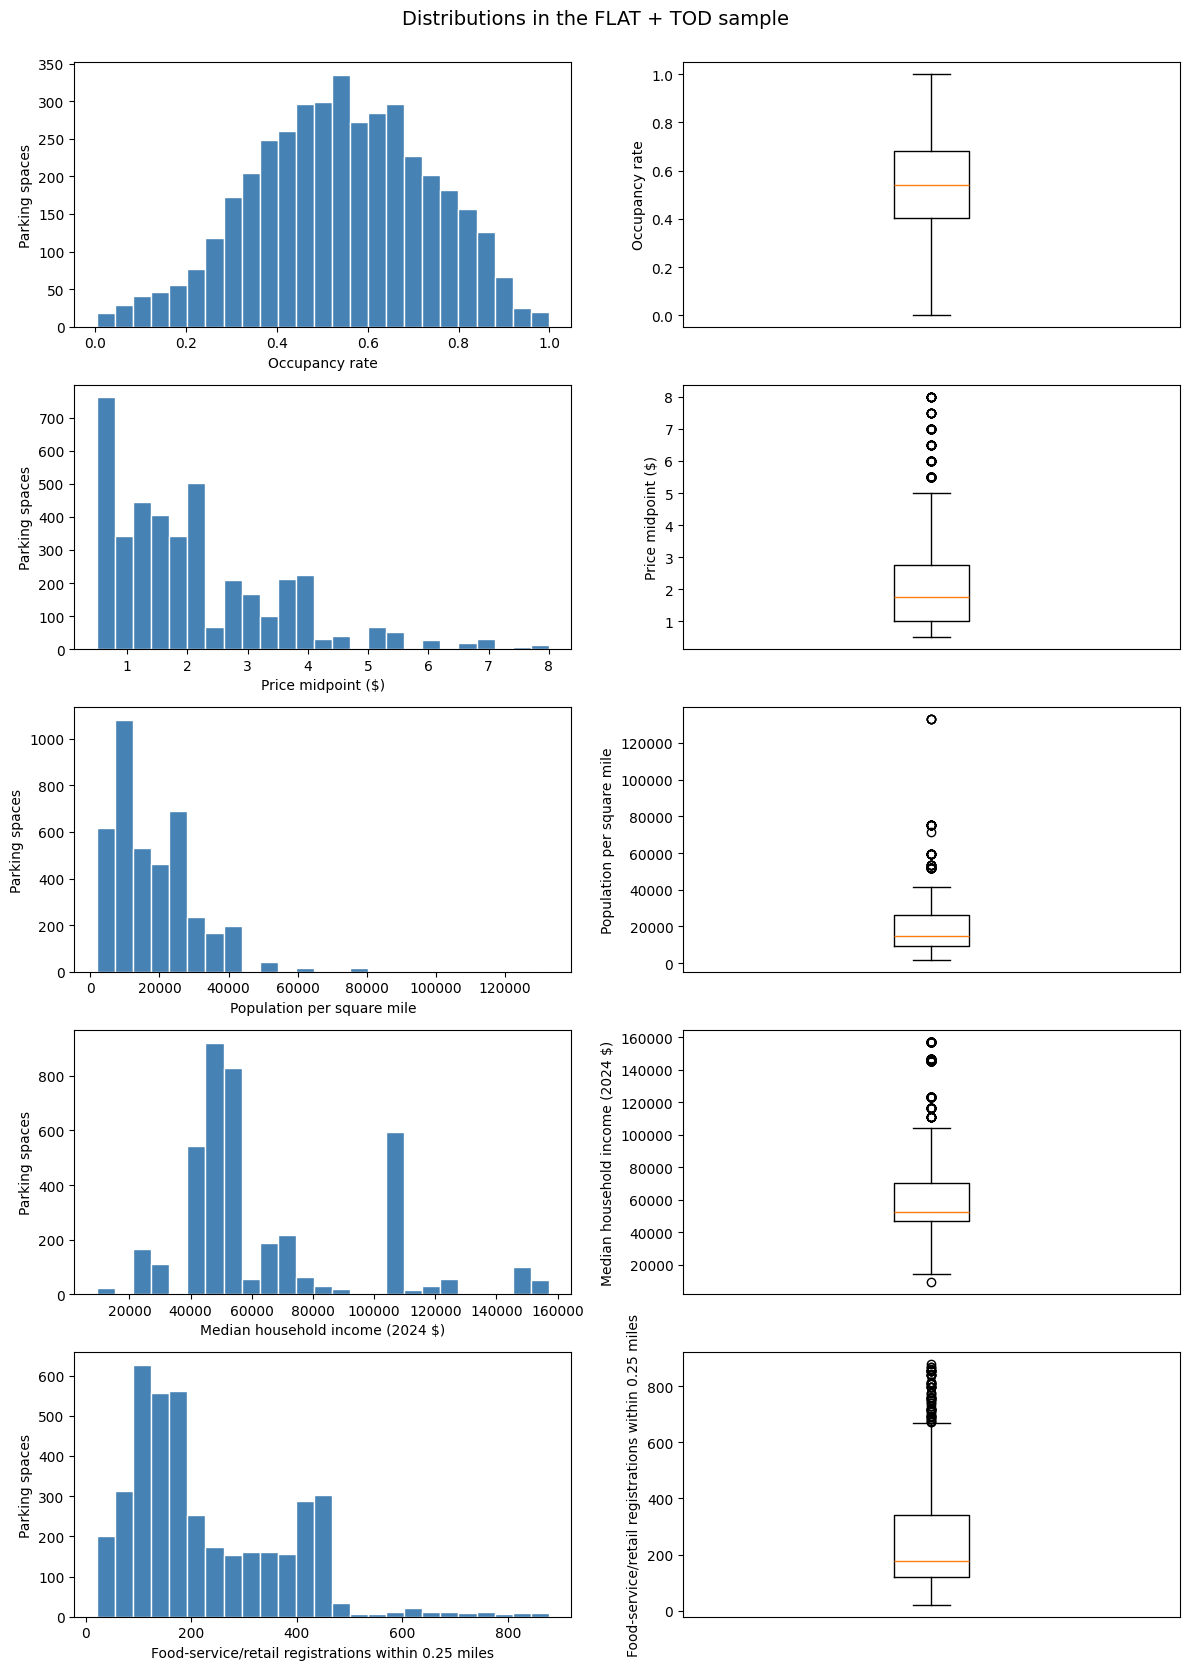

In [9]:
plot_variables = [
    "occupancy_rate", "price_midpoint", "population_density",
    "median_income", "nearby_restaurant_retail_count"
]
plot_labels = [
    "Occupancy rate", "Price midpoint ($)",
    "Population per square mile", "Median household income (2024 $)",
    "Food-service/retail registrations within 0.25 miles"
]

fig, axes = plt.subplots(5, 2, figsize=(12, 17))

for i, variable in enumerate(plot_variables):
    values = parking[variable].dropna()
    axes[i, 0].hist(values, bins=25, color="steelblue", edgecolor="white")
    axes[i, 0].set_xlabel(plot_labels[i])
    axes[i, 0].set_ylabel("Parking spaces")
    axes[i, 1].boxplot(values)
    axes[i, 1].set_ylabel(plot_labels[i])
    axes[i, 1].set_xticks([])

fig.suptitle("Distributions in the FLAT + TOD sample", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

Occupancy is spread across most of the zero-to-one range rather than concentrated at either endpoint. Price is discrete, and population density and business counts have visible upper tails. The boxplot markers identify values to inspect, not observations to delete; predictors do not need to be normally distributed for OLS.

## 7. Explore occupancy relationships

I compare occupancy with price, population density, income, food-service/retail registrations, and the drive-alone share. Transparent points help with overlap, but repeated tract values and discrete prices still create vertical bands. These are unadjusted relationships; I do not fit regression lines or interpret them as causal effects.

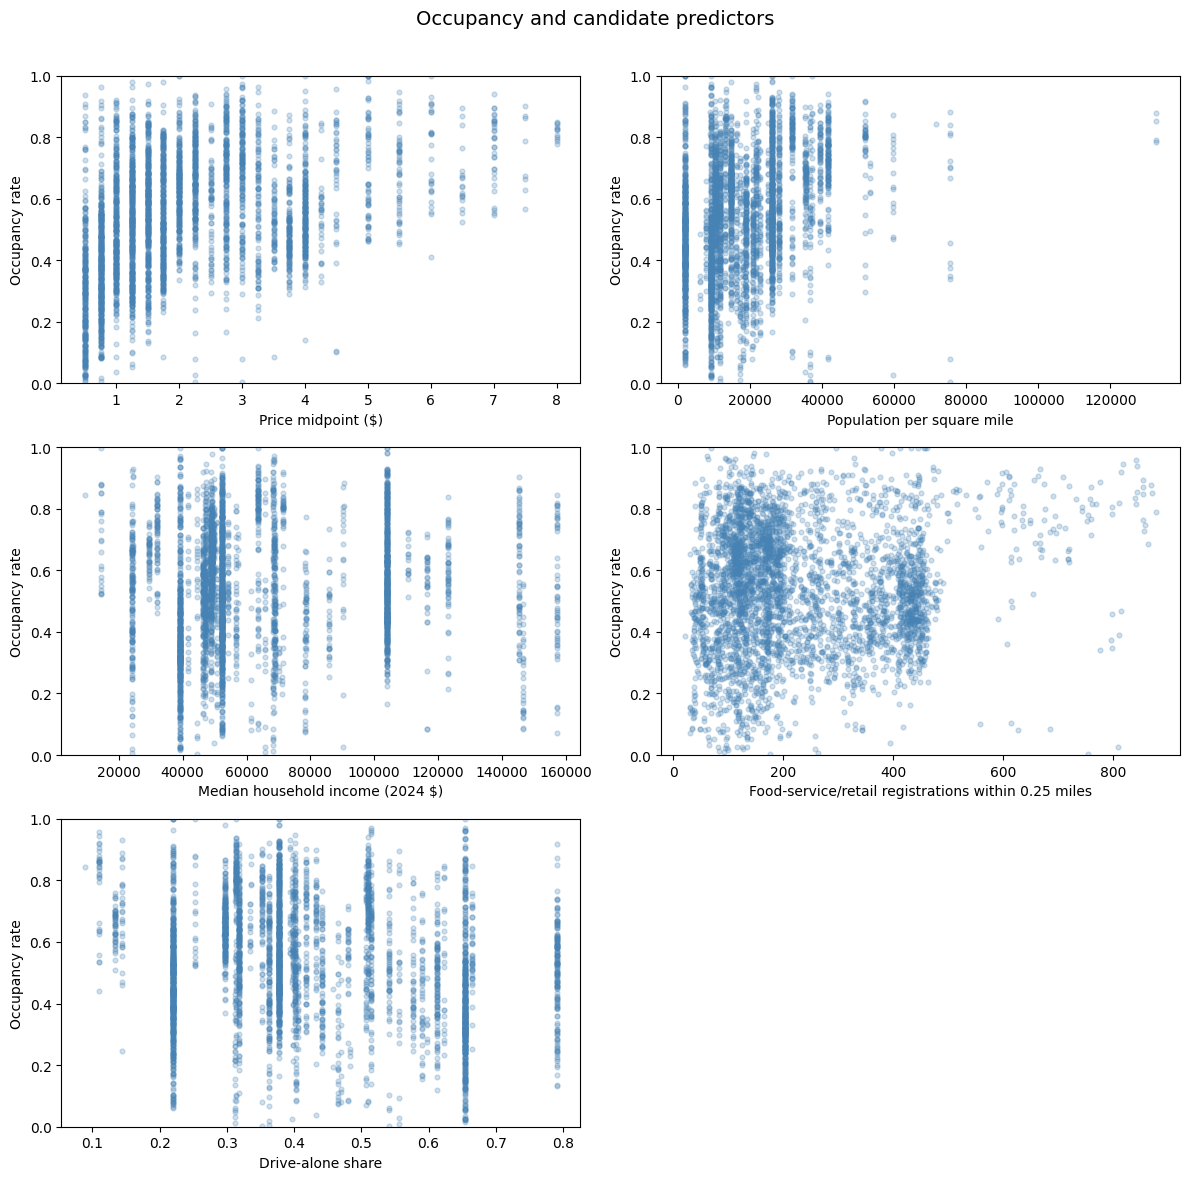

In [10]:
scatter_variables = [
    "price_midpoint", "population_density", "median_income",
    "nearby_restaurant_retail_count", "drive_alone_share"
]
scatter_labels = [
    "Price midpoint ($)", "Population per square mile",
    "Median household income (2024 $)",
    "Food-service/retail registrations within 0.25 miles",
    "Drive-alone share"
]

fig, axes = plt.subplots(3, 2, figsize=(12, 12))
axes = axes.flatten()

for i, variable in enumerate(scatter_variables):
    axes[i].scatter(
        parking[variable], parking[dependent_variable],
        s=12, alpha=0.25, color="steelblue"
    )
    axes[i].set_xlabel(scatter_labels[i])
    axes[i].set_ylabel("Occupancy rate")
    axes[i].set_ylim(0, 1)

axes[5].axis("off")
fig.suptitle("Occupancy and candidate predictors", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

The price and density plots suggest positive overall associations, but occupancy varies widely at the same predictor value. Any curved pattern or difference in spread needs closer inspection before choosing a functional form; these plots do not establish a particular nonlinearity. Price may respond to local demand, and its later vintage is another reason to avoid a causal interpretation.

## 8. Compare correlations

I calculate Pearson correlations for the outcome and numeric candidates, including the additional density and business measures for comparison. Pandas uses available pairs: correlations involving income use 4,016 spaces and the other pairs use 4,060. The table and heatmap help identify overlapping information, not select the final predictors.

In [11]:
correlations = parking[numeric_variables].corr()
correlations.round(3)

,occupancy_rate,price_midpoint,time_limit_hours,population_density,median_income,nearby_restaurant_retail_count,drive_alone_share,housing_density,transit_share,walk_share,nearby_business_count
occupancy_rate,1.000,0.394,-0.089,0.322,0.073,0.080,-0.197,0.295,-0.092,0.260,0.192
price_midpoint,0.394,1.000,-0.238,0.218,0.105,0.545,-0.341,0.281,-0.077,0.207,0.586
time_limit_hours,-0.089,-0.238,1.000,-0.067,-0.080,-0.089,0.095,-0.037,0.204,-0.122,-0.099
population_density,0.322,0.218,-0.067,1.000,0.131,0.130,0.094,0.925,0.029,0.047,0.185
median_income,0.073,0.105,-0.080,0.131,1.000,-0.014,-0.106,0.241,-0.593,-0.072,0.019
nearby_restaurant_retail_count,0.080,0.545,-0.089,0.130,-0.014,1.000,-0.398,0.279,0.050,0.143,0.898
drive_alone_share,-0.197,-0.341,0.095,0.094,-0.106,-0.398,1.000,0.023,0.360,-0.687,-0.471
housing_density,0.295,0.281,-0.037,0.925,0.241,0.279,0.023,1.000,-0.019,-0.043,0.329
transit_share,-0.092,-0.077,0.204,0.029,-0.593,0.050,0.360,-0.019,1.000,-0.363,-0.061
walk_share,0.260,0.207,-0.122,0.047,-0.072,0.143,-0.687,-0.043,-0.363,1.000,0.279


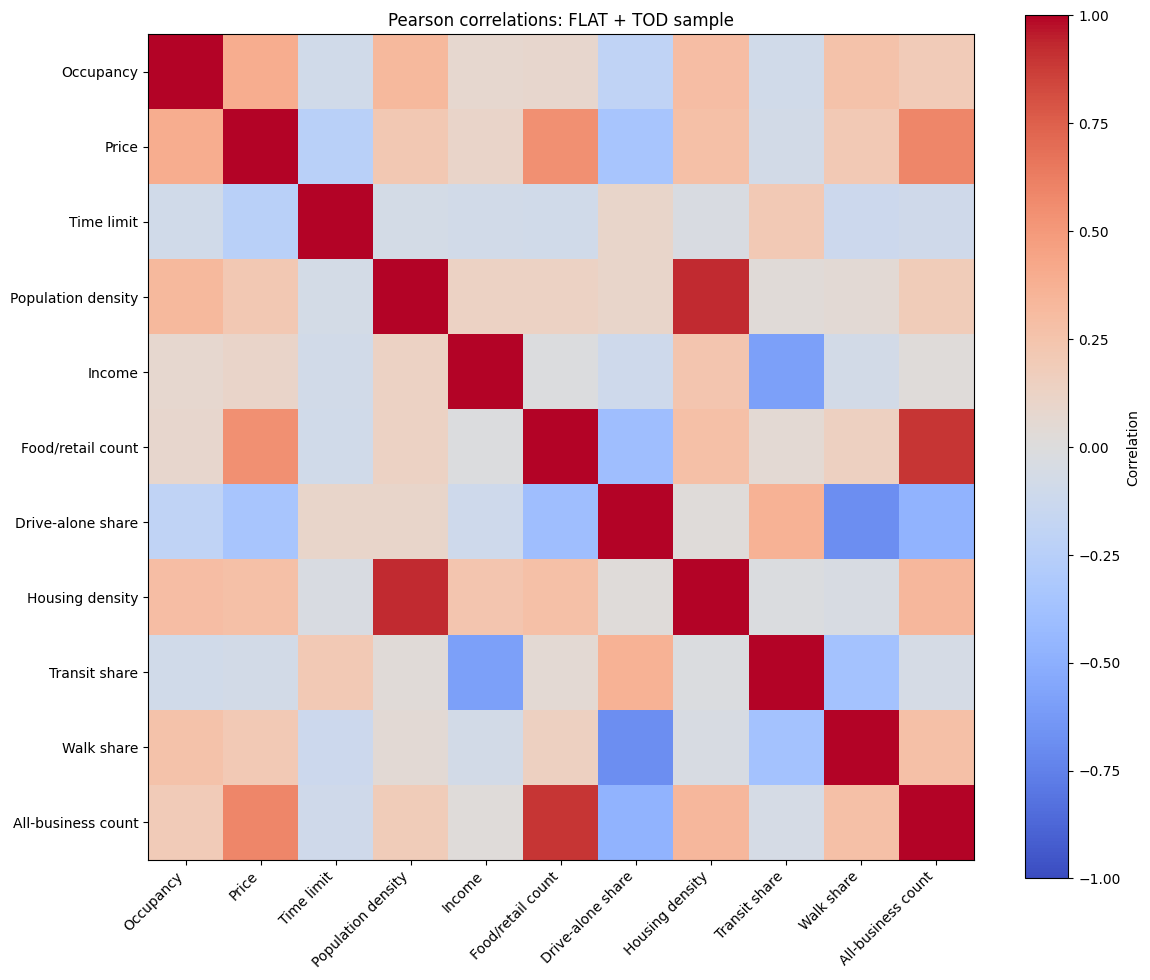

In [12]:
correlation_labels = [
    "Occupancy", "Price", "Time limit", "Population density", "Income",
    "Food/retail count", "Drive-alone share", "Housing density",
    "Transit share", "Walk share", "All-business count"
]

fig, ax = plt.subplots(figsize=(12, 10))
heatmap = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation_labels)), labels=correlation_labels,
              rotation=45, ha="right")
ax.set_yticks(range(len(correlation_labels)), labels=correlation_labels)
ax.set_title("Pearson correlations: FLAT + TOD sample")
fig.colorbar(heatmap, ax=ax, label="Correlation")
fig.tight_layout()
plt.show()

Population and housing density are strongly correlated (0.925), as are the all-business and food-service/retail counts (0.898). Price also correlates with food-service/retail activity (0.545) and all-business activity (0.586). I therefore avoid treating these related measures as automatically separate sources of information in a preferred model.

Occupancy correlates positively with price (0.394), but the food-service/retail correlation is only 0.080. Neither result identifies a causal effect or tells us what a coefficient will be after controls. A small pairwise correlation alone is not grounds for discarding an economically relevant candidate.

## 9. Flag extreme values without removing them

I use the usual 1.5-IQR fences as a descriptive screen, alongside the histograms and boxplots. The percentage below uses the nonmissing count for each variable. The rule can flag ordinary values for discrete variables, so it is not an automatic cleaning rule.

In [13]:
q1 = parking[numeric_variables].quantile(0.25)
q3 = parking[numeric_variables].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

outside_fences = (
    parking[numeric_variables].lt(lower_fence)
    | parking[numeric_variables].gt(upper_fence)
)

iqr_check = pd.DataFrame({
    "observed_count": parking[numeric_variables].count(),
    "lower_fence": lower_fence,
    "upper_fence": upper_fence,
    "outside_count": outside_fences.sum(),
    "outside_percent": outside_fences.sum() / parking[numeric_variables].count() * 100
})

iqr_check.round(3)

,observed_count,lower_fence,upper_fence,outside_count,outside_percent
occupancy_rate,4060,-0.012,1.094,0,0.000
price_midpoint,4060,-1.625,5.375,150,3.695
time_limit_hours,4060,2.000,2.000,1160,28.571
population_density,4060,-16260.332,51723.607,79,1.946
median_income,4016,11924.000,105332.000,251,6.250
nearby_restaurant_retail_count,4060,-212.500,671.500,59,1.453
drive_alone_share,4060,0.008,0.818,0,0.000
housing_density,4060,-16062.409,42621.149,36,0.887
transit_share,4060,-0.083,0.274,0,0.000
walk_share,4060,-0.134,0.371,82,2.020


The screen flags 150 price values, 79 population-density values, 251 observed incomes, and 59 food-service/retail counts. For time limits, both quartiles equal two hours, so the zero IQR flags all 1,160 non-two-hour values; that is a limitation of the screen, not evidence those limits are wrong. I inspect high-density tracts and high business counts below without removing them.

In [14]:
tract_extremes = parking.groupby("GEOID").agg(
    spaces=("SpaceID", "size"),
    population_density=("population_density", "first"),
    housing_density=("housing_density", "first"),
    median_income=("median_income", "first")
)

tract_extremes.sort_values("population_density", ascending=False).head(5).round(2)

,spaces,population_density,housing_density,median_income
GEOID,,,,
06037207304,4,132736.84,101157.89,14342.0
06037207307,15,75368.42,69894.74,NaN
06037206302,1,71611.11,43222.22,9375.0
06037207308,16,59666.67,53333.33,90156.0
06037265306,6,53333.33,14861.11,57188.0


In [15]:
parking.nlargest(5, "nearby_restaurant_retail_count")[[
    "SpaceID", "BlockFace", "nearby_restaurant_retail_count",
    "nearby_business_count", "occupancy_rate"
]]

,SpaceID,BlockFace,nearby_restaurant_retail_count,nearby_business_count,occupancy_rate
1466,CB3648B,501 SPRING ST,878,4467,0.789179
1468,CB3651,601 SPRING ST,870,4457,0.851962
1465,CB3648,501 SPRING ST,868,4406,0.878580
1912,CB4371,600 SPRING ST,862,4435,0.684367
1909,CB4368,600 SPRING ST,858,4399,0.746714


The highest population and housing densities occur in a small downtown tract, so repeated extreme values can reflect a shared tract characteristic. High registration counts also deserve attention because multiple accounts may share an address. These are reasons to inspect interpretation, not to assume bad records.

Simple logs of positive density or business counts may be worth comparing later because of their right tails. I do not create transformed variables here or choose transformations to improve correlations. No values are winsorized, imputed, or removed by the outlier checks.

## 10. Summarize the EDA and hand off to Notebook 05

The main sample has **4,060 spaces**, after excluding 79 JUMP meters from the original 4,139. Mean time-weighted occupancy is about **0.539**. I explored price, time limits, population density, income, food-service/retail registrations, drive-alone share, and the additional meter, housing, commuting, and all-business candidates.

Income is missing for **44 spaces (1.08%)** in two tracts. The separate complete-case copy for the primary candidate list has **4,016 spaces**; the initial EDA sample keeps the missing incomes. Zoning is excluded from the analysis lists because of incomplete coverage, without deleting rows.

Price, density, income, and business measures have right tails. The density pair (0.925) and business-count pair (0.898) are strongly correlated, and price is related to commercial activity. The scatterplots show substantial variation and possible changes in shape or spread, but do not establish a nonlinear specification. Extreme densities and registration counts need careful interpretation rather than automatic trimming.

Notebook 05 should compare a small set of economically motivated candidates, using the food-service/retail count as the primary commercial measure and documenting each model's complete-case sample. Final predictor selection, categorical encoding, transformations, and regressions have not been performed. The 2026 price and business snapshots remain proxies for conditions around the August 2025 outcome.

Later robustness analysis should compare **12-, 24-, and 48-hour interval cutoffs**, **20-, 25-, and 28-active-day samples**, and **Sunday-reporting differences**. Those alternatives are not rebuilt here. All samples in this notebook stay in memory; the original processed cross-section and Notebooks 01–03 remain unchanged.

In [16]:
print("Original cross-section:", parking_full.shape)
print("Main EDA sample:", parking.shape)
print("Income-complete comparison:", income_sample.shape)
print("Main sample unique SpaceIDs:", parking["SpaceID"].nunique())
print("Main sample duplicate SpaceIDs:", parking["SpaceID"].duplicated().sum())

Original cross-section: (4139, 36)
Main EDA sample: (4060, 36)
Income-complete comparison: (4016, 36)
Main sample unique SpaceIDs: 4060
Main sample duplicate SpaceIDs: 0
